In [2]:
from google.colab import files
import zipfile
import pandas as pd
import io
import os

uploaded = files.upload()

zip_name = next(iter(uploaded))

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name]), "r") as z:
    print("Files inside ZIP:", z.namelist())
    csv_name = next(name for name in z.namelist() if name.endswith(".csv"))
    with z.open(csv_name) as f:
        df = pd.read_csv(f)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())

Saving india_weather_data.csv.zip to india_weather_data.csv.zip
Files inside ZIP: ['india_weather_data.csv']
Dataset loaded successfully!
Shape: (131055, 18)
                  date  latitude  longitude  wind_speed  cloud_cover  \
0  2023-01-01 00:00:00   28.6139    77.2090    0.428064    56.787047   
1  2023-01-01 00:00:00   19.0760    72.8777   13.603933    36.321945   
2  2023-01-01 00:00:00   12.9716    77.5946  100.000000    49.585297   
3  2023-01-01 00:00:00   22.5726    88.3639    2.785259    21.462155   
4  2023-01-01 00:00:00       NaN    80.2707    9.399230          NaN   

   precipitation_probability  pressure_surface_level  dew_point  uv_index  \
0                  89.803147             1003.885666  29.282458  6.353398   
1                  75.198203              500.000000        NaN  6.653509   
2                  60.621663             1001.774831  31.567394  5.976996   
3                  38.284893              993.455514  29.974869  7.757285   
4                  21.53

In [3]:
import math

x = df["max_temperature"]
y = df["min_temperature"]

weather = pd.DataFrame({"X": x, "Y": y}).dropna()

x = weather["X"].tolist()
y = weather["Y"].tolist()

n = len(x)
mean_x = sum(x) / n
mean_y = sum(y) / n

numerator = sum(
    (x[i] - mean_x) * (y[i] - mean_y)
    for i in range(n)
)

denominator = math.sqrt(
    sum((a - mean_x) ** 2 for a in x) *
    sum((b - mean_y) ** 2 for b in y)
)

r = numerator / denominator

print("Number of valid records:", n)
print("Correlation coefficient:", round(r, 4))

if r > 0:
    print("Positive correlation")
elif r < 0:
    print("Negative correlation")
else:
    print("No linear correlation")

Number of valid records: 106361
Correlation coefficient: 0.9727
Positive correlation


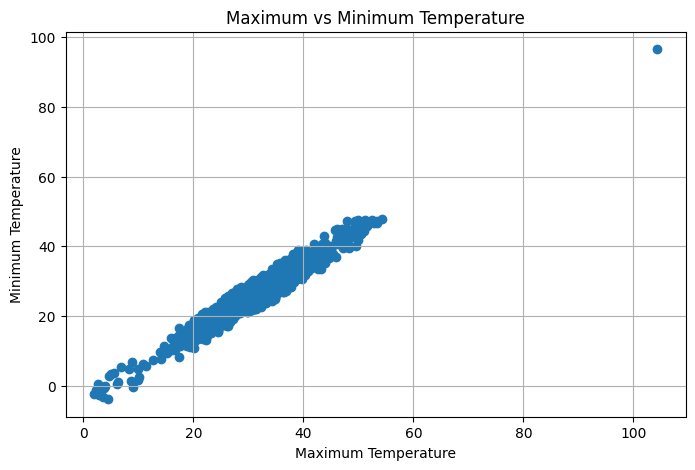

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(x[::100], y[::100])
plt.title("Maximum vs Minimum Temperature")
plt.xlabel("Maximum Temperature")
plt.ylabel("Minimum Temperature")
plt.grid(True)
plt.show()

Positive Correlation: 1.0


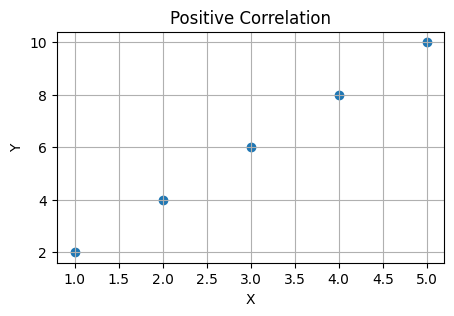

Negative Correlation: -1.0


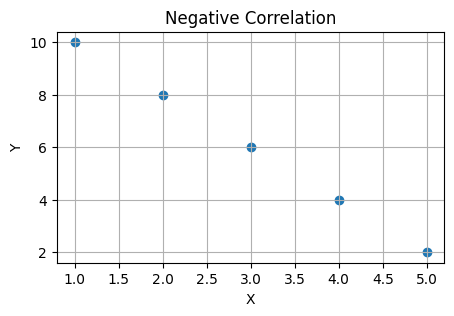

No Linear Correlation: 0.0


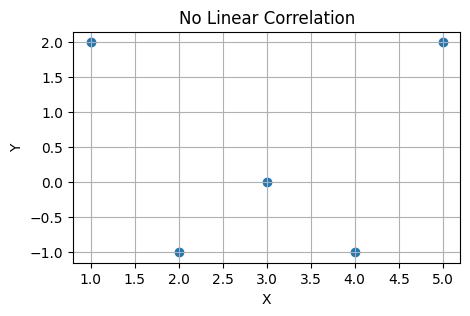

In [5]:
import matplotlib.pyplot as plt

x_demo = [1, 2, 3, 4, 5]

datasets = {
    "Positive Correlation": [2, 4, 6, 8, 10],
    "Negative Correlation": [10, 8, 6, 4, 2],
    "No Linear Correlation": [2, -1, 0, -1, 2]
}

for title, y_demo in datasets.items():
    n = len(x_demo)
    mx = sum(x_demo) / n
    my = sum(y_demo) / n

    num = sum((x_demo[i] - mx) * (y_demo[i] - my)
              for i in range(n))
    den = math.sqrt(
        sum((a - mx) ** 2 for a in x_demo) *
        sum((b - my) ** 2 for b in y_demo)
    )

    r = num / den if den else 0
    print(title + ":", round(r, 2))

    plt.figure(figsize=(5, 3))
    plt.scatter(x_demo, y_demo)
    plt.title(title)
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(True)
    plt.show()